In [43]:
import os
import numpy as np
import uproot
import sys

import matplotlib.pyplot as plt

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

import iminuit

from v2Helpers import *

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

In [44]:
g4BasePath = os.environ.get("CF4G4")
print(g4BasePath)

/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/


### Compare with MC
I need to do two runs, one with LP and one bare. apply same 'rate scaling' to both datasets.

In [45]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME")+"/comp1/helpers/")
import Comparator as comp
import MCdataSet as mcd
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

# ------------- User Inputs ------------- #
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = False
DO_2D = False
QVAR_USE = "qFixed"
PECUTVALUE = 0.5

defPath = str(os.environ["CF4HOME"]) + "/procData/"
rootPath = defPath + "/analysis1/"

runID_lp = [202206231023]
runID_bare = [202205201136]
physicsList = runID_bare + runID_lp
allRuns = physicsList

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Users/austindestcroix/Library/Python/3.11/lib/python/site-packages', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/helpers/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/Batch/hel

In [46]:
# ------------- Main Analysis ------------- #
rcList = []
fList = []

for run in allRuns:
    file_path = rootPath + f"npv1_{run}.root"
    f = ROOT.TFile(file_path, "READ")
    fList.append(f)
    tt = f.Get("tt")
    
    rcObj = RunClass(run, tt, fname = file_path)
    rcList.append(rcObj)
    
    rcObj.computeSPE(width=25, verbose=VERBOSE, varname=QVAR_USE, channels=[i for i in range(NCHAN)], nbins = 150)
    rcObj.UprootConstructor()
    # rcList.append(rcObj)

if VERBOSE:
    input("say something to move past bkg SPE plots")

for rc in rcList:
    rc.print()

rcBare = SORTING.pickSingleRC(runID_bare[0], rcList)
rcLp = SORTING.pickSingleRC(runID_lp[0], rcList)



runID: 202205201136
Nevents: 217499.00,   time: 0.65 min
average Rate: 5558.14 Hz
chID:0: spe = 141.61 +/- 0.19     maxChi2 = 185.06
chID:1: spe = 146.16 +/- 0.10     maxChi2 = 398.40
chID:2: spe = 149.26 +/- 0.08     maxChi2 = 464.40

runID: 202206231023
Nevents: 515499.00,   time: 1.19 min
average Rate: 7243.99 Hz
chID:0: spe = 143.92 +/- 0.04     maxChi2 = 4202.59
chID:1: spe = 145.31 +/- 0.05     maxChi2 = 1471.11
chID:2: spe = 148.70 +/- 0.04     maxChi2 = 3135.43


Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full


2
['chInfo', 'evTime', 'blineV', 'blineE', 'minV', 'timeMin', 'qFixed', 'qFlat', 'tFlatStart', 'tFlatEnd', 'qRCFixed', 'qRCFlat']
<TBranch 'qFixed' at 0x00032e5cd150>


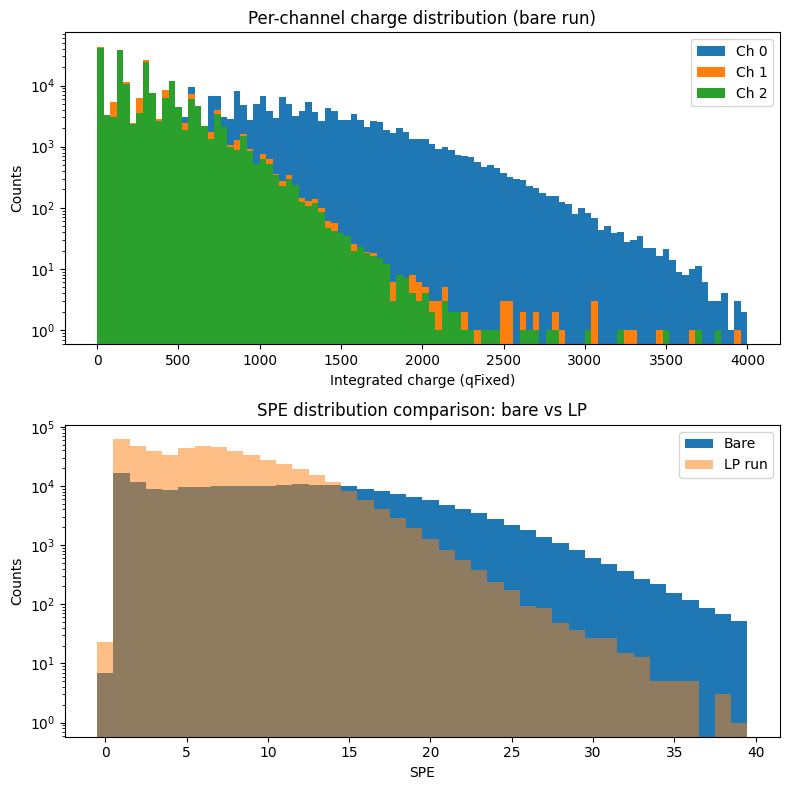

In [47]:
print(len(rcList))

print(rcBare.mttUp.keys())
print(rcBare.mttUp["qFixed"])

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

# for rc in rcList:
#   qa = rc.GetSPEValues(qvar=QVAR_USE)

########################
fig, (axQ, axS) = plt.subplots(2, 1, figsize=(8, 8))

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

binEdge = np.linspace(0, 4000, 101)
axQ.hist(qraw[:, 0], bins=binEdge, label="Ch 0")
axQ.hist(qraw[:, 1], bins=binEdge, label="Ch 1")
axQ.hist(qraw[:, 2], bins=binEdge, label="Ch 2")
axQ.legend()
axQ.set_title("Per-channel charge distribution (bare run)")
axQ.set_xlabel("Integrated charge (qFixed)")
axQ.set_ylabel("Counts")
axQ.set_yscale("log")

bE = np.linspace(-0.5, 39.5, 41)

zBare = axS.hist(rcBare.GetSPEArray(), bins=bE, label = "Bare")
zLP = axS.hist(rcLp.GetSPEArray(), bins=bE, alpha = 0.5, histtype="stepfilled", label = "LP run")

axS.set_title("SPE distribution comparison: bare vs LP")
axS.set_xlabel("SPE")
axS.set_ylabel("Counts")
axS.set_yscale("log")

# axS.set_xlim(4, 10)

# axS.set_yscale("log")
axS.legend()
plt.tight_layout()
plt.show()
# axS.set_yscale("log")

In [48]:
## inspect zBare

print(len(zBare))
print(zBare[0][0:10])
print(zBare[1][0:10])
binCenters = 0.5 * (zBare[1][1:] + zBare[1][:-1])

## find bin position for 5, 6, 7, 8
binMask = (binCenters > 4) & (binCenters < 11)
print(binMask)

print("binX centers: ", binCenters[binMask])
print("binY counts: ", zBare[0][binMask])

3
[7.0000e+00 1.6301e+04 1.1557e+04 8.7470e+03 8.4100e+03 9.4320e+03
 9.7360e+03 1.0110e+04 9.9600e+03 9.9180e+03]
[-0.5  0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5]
[False False False False False  True  True  True  True  True  True False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False]
binX centers:  [ 5.  6.  7.  8.  9. 10.]
binY counts:  [ 9432.  9736. 10110.  9960.  9918.  9915.]


---
### Workflow
? 'rate scaling' - R ?
look at absolute rates and if not very different, ignore. just fit spectrum

Light yield - Y

UV fraction - f

okay, looks like rates dont make sense. lets assume its from digitizer busy haha. just do vertical scaling

In [49]:
## usually use config.json file to organize all this
class storeConfig:
  pass
conf = storeConfig()
conf.NCA = 0.17
conf.binLow = -0.5
conf.binHigh = 39.5
conf.binWidth = 1.0
conf.Nbins = int((conf.binHigh - conf.binLow) / conf.binWidth)
print(f"Nbins: {conf.Nbins}")

## fitting ranges
conf.rangeLow = 5
conf.rangeHigh = 12

conf.rangeLowBare = 10
conf.rangeHighBare = 20
conf.compNbins = int((conf.rangeHigh - conf.rangeLow) / conf.binWidth)
conf.compNbinsBare = int((conf.rangeHighBare - conf.rangeLowBare) / conf.binWidth)
print(f"comp Nbins: {conf.compNbins}")

Nbins: 40
comp Nbins: 7


/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/4/Alpha_vf_0d9_bare.root
0.21963184362842775


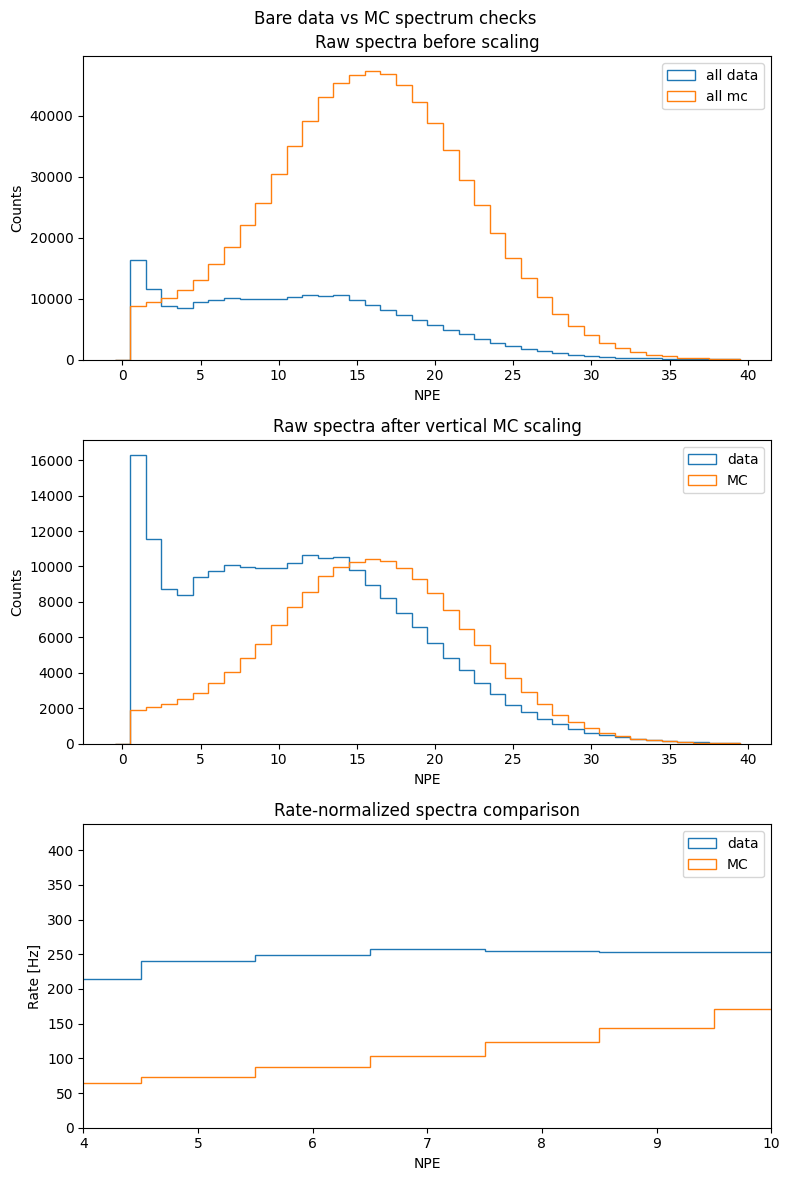

In [50]:
## load in MC data, compare to data
g4BasePath = os.environ.get("CF4G4")
print(g4BasePath)
sys.path.append(g4BasePath + "/Batch/helpers")
import G4_runClasses as g4rc
import Comparator as g4comp
g4Path = g4BasePath + "batchOutput/alpha_sept25"

## controlling the bins ##
binsDict = {"nbins": conf.Nbins, "low": 5, "high": conf.binHigh}
compBinsDict = {"firstBin": conf.rangeLowBare, "lastBin": conf.rangeHighBare, "nbins": conf.compNbins, "mode":"x"}

## load MC data
mcBare_test = g4rc.FullMCRun(macName = g4Path+"/4/Alpha_vf_0d9_bare")
mcBare_test.doCAcorrection_BinomialMC(nCA = conf.NCA)
# mcBare_test.doCAcorrection_GeometricMC(nCA = conf.NCA)

## these should have same bin sizes
mcBare_test.setup_forComparison(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, variable = "mNPE")
rcBare.setup_forComparison_np(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, qvar=QVAR_USE, peCut=PECUTVALUE)

## plotting
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12))
fig.suptitle("Bare data vs MC spectrum checks")

ax1.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rawCounts, histtype="step", label = "all data")
ax1.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = mcBare_test.mRaw_Counts, histtype="step", label = "all mc")
ax1.set_title("Raw spectra before scaling")
ax1.set_xlabel("NPE")
ax1.set_ylabel("Counts")
ax1.legend()

## build rc mc pair
testPair = g4comp.rcMCpair(rcBare, mcBare_test)
testPair.SetBinRanges(firstBin = conf.rangeLowBare, lastBin = conf.rangeHighBare, mode="x")

# ## guess the rate scaling
scaleMC = testPair.GuessScaling() * testPair.GetPrefac()
print(scaleMC)

# scaleMC = fixRcMc.GetPrefac() * fixRcMcPair.GuessScaling()
# ## plotting ##
ax2.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rawCounts, histtype="step", label = "data");
ax2.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = scaleMC * mcBare_test.mRaw_Counts, histtype="step", label = "MC");

ax2.set_title("Raw spectra after vertical MC scaling")
ax2.set_xlabel("NPE")
ax2.set_ylabel("Counts")
ax2.legend()

ax3.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rate, histtype="step", label = "data");
ax3.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = mcBare_test.mRaw_Counts * scaleMC / rcBare.GetRunTime(), histtype="step", label = "MC");
ax3.set_title("Rate-normalized spectra comparison")
ax3.set_xlabel("NPE")
ax3.set_ylabel("Rate [Hz]")
ax3.legend()

ax3.set_xlim(4, 10)
plt.tight_layout()

---
## need to make some new tools/plan here

1. hold both the LP and Bare data, and corresponding MC runs
2. wont do any rate scaling. and scaling LY is challenging because integer to float thing
3. simple solution. Fit both bare and LP MC spectra (high ends) with a gaussian. see how much to scale horizontally to fit the data's tail. 
4. scaling x LY gives actual LY
5. best fit mc dataset gives UV and Vis fraction 

In [51]:
## Gaussian fitting with iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares
import scipy.stats as stats

# Example: Fit the MC histogram
print("Fitting MC histogram with Gaussian...")

# Get the MC histogram data
mc_bin_centers = mcBare_test.mBinX
mc_counts = mcBare_test.mRaw_Counts * scaleMC  # use the scaled counts

# Only fit in the range where we have reasonable statistics
fit_mask = (mc_bin_centers >= conf.rangeLowBare) & (mc_bin_centers <= conf.rangeHighBare) & (mc_counts > 0)
# fit_maskBare = (rcBare.mBinX >= conf.rangeLowBare) & (rcBare.mBinX <= conf.rangeHighBare) & (rcBare.mBin_rawCounts > 0)
mc_centers_fit = mc_bin_centers[fit_mask]
mc_counts_fit = mc_counts[fit_mask]

# Perform the fit
mc_fit_result = fit_histogram_gaussian(mc_centers_fit, mc_counts_fit)

print(f"MC Fit Results:")
print(f"Amplitude: {mc_fit_result.values['amplitude']:.2f} ± {mc_fit_result.errors['amplitude']:.2f}")
print(f"Mean: {mc_fit_result.values['mean']:.2f} ± {mc_fit_result.errors['mean']:.2f}")
print(f"Sigma: {mc_fit_result.values['sigma']:.2f} ± {mc_fit_result.errors['sigma']:.2f}")
print(f"Chi2/ndf: {mc_fit_result.fval:.2f}/{len(mc_centers_fit) - 3}")

# Check if fit is valid
if mc_fit_result.valid:
    print("✓ Fit converged successfully")
else:
    print("✗ Fit did not converge properly")

Fitting MC histogram with Gaussian...
MC Fit Results:
Amplitude: 10438.08 ± 46.50
Mean: 15.95 ± 0.05
Sigma: 6.34 ± 0.09
Chi2/ndf: 1.92/8
✓ Fit converged successfully


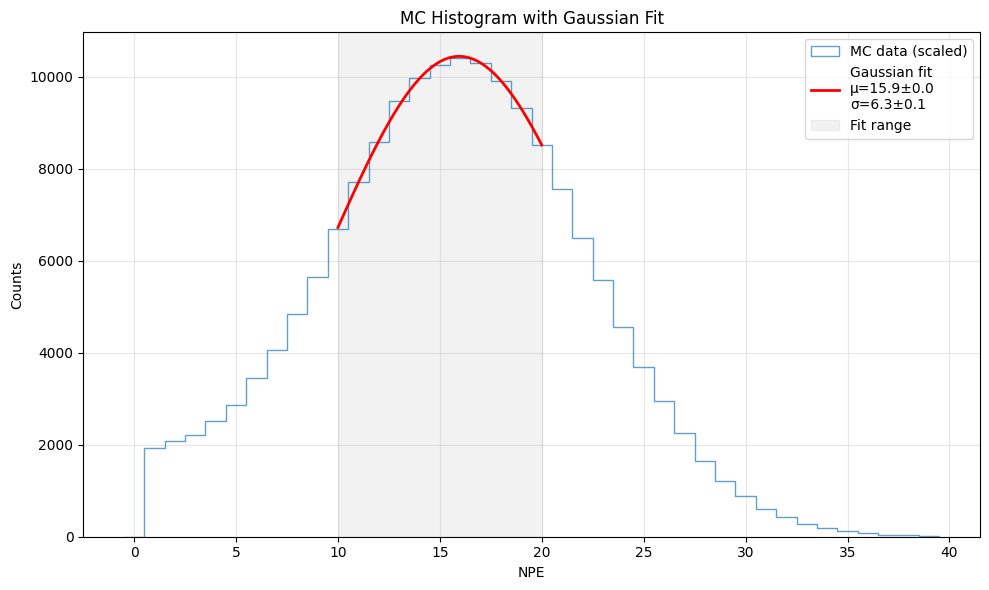


Covariance matrix:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1.918 (χ²/ndof = 0.2)      │              Nfcn = 89               │
│ EDM = 2.22e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─

In [52]:
# Plot the fit result
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the original histogram
ax.hist(mc_bin_centers, bins=mcBare_test.mBin_Edges, weights=mc_counts, 
        histtype="step", label="MC data (scaled)", alpha=0.7)

# Generate smooth curve for the fit
x_smooth = np.linspace(conf.rangeLowBare, conf.rangeHighBare, 200)
y_fit = gaussian(x_smooth, 
                mc_fit_result.values['amplitude'], 
                mc_fit_result.values['mean'], 
                mc_fit_result.values['sigma'])

# Plot the fit
ax.plot(x_smooth, y_fit, 'r-', linewidth=2, 
        label=f'Gaussian fit\nμ={mc_fit_result.values["mean"]:.1f}±{mc_fit_result.errors["mean"]:.1f}\nσ={mc_fit_result.values["sigma"]:.1f}±{mc_fit_result.errors["sigma"]:.1f}')

# Plot just the fitted region for clarity
ax.axvspan(conf.rangeLowBare, conf.rangeHighBare, alpha=0.1, color='gray', label='Fit range')

ax.set_xlabel('NPE')
ax.set_ylabel('Counts')
ax.set_title('MC Histogram with Gaussian Fit')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print covariance matrix (uncertainties)
print("\nCovariance matrix:")
print(mc_fit_result)

---
## MC fitting
Okay. lets do this. I need to loop through the folders in g4path, and open both the .root files (LP and bare).

1. open them as g4rc.FullMCRun(macName = g4Path+"/Alpha_vf_0d9_bare"), but you will need to find the filename programmatically
2. setup for comparison, usign the same bin config as above
3. make a wrapper function, so i can pass my mc object to fit the gaussian simply/easily
4. fit both root files. output the resulting fit params

okay now it gets a bit more complicated. i need to scale the x axis of the mc fits to compare to the data.
1. make a function that computes the chi2 between a given hisogram (data) and given mc fits. Each fit can be scaled vertically, but they have to share a common horizontal scaling. so 3 free parameters. Sbare, SLP, and LYscale. Minimize the output of this function.
2. apply this function in the loop over folders (happens for each folder)

In [53]:
import glob
import os

def chi2_data_mc_flexsigma(params, data_bare_hist, data_lp_hist, mean_bare_MC, mean_ratio, bin_centers):
  """
  flexSigma variant: fit two Gaussians directly to data.

  Fixed:  mean_ratio = mu_LP_MC / mu_bare_MC  (from MC Gaussian fits)
  Free:   Abare, ALP       - amplitudes for bare / LP
          LYscale          - shared horizontal scale  (mu_data = LYscale * mu_MC)
          sigma_bare        - Gaussian width for bare data fit
          sigma_lp          - Gaussian width for LP   data fit

  Model in data space:
      bare: gaussian(x, Abare, LYscale * mean_bare_MC,               sigma_bare)
      LP:   gaussian(x, ALP,   LYscale * mean_bare_MC * mean_ratio,  sigma_lp)
  """
  Abare, ALP, LYscale, sigma_bare, sigma_lp = params

  mu_bare = LYscale * mean_bare_MC
  mu_lp   = LYscale * mean_bare_MC * mean_ratio

  pred_bare = gaussian(bin_centers, Abare, mu_bare, sigma_bare)
  pred_lp   = gaussian(bin_centers, ALP,   mu_lp,   sigma_lp)

  fit_maskBare = (bin_centers >= conf.rangeLowBare) & (bin_centers <= conf.rangeHighBare)
  fit_mask     = (bin_centers >= conf.rangeLow)     & (bin_centers <= conf.rangeHigh)

  err_bare = np.sqrt(data_bare_hist[fit_maskBare]); err_bare[err_bare == 0] = 1
  err_lp   = np.sqrt(data_lp_hist[fit_mask]);       err_lp[err_lp   == 0] = 1

  chi2_bare = np.sum((data_bare_hist[fit_maskBare] - pred_bare[fit_maskBare])**2 / err_bare**2)
  chi2_lp   = np.sum((data_lp_hist[fit_mask]       - pred_lp[fit_mask])**2       / err_lp**2)

  return chi2_bare + chi2_lp


def fit_ly_flexsigma_iminuit(data_bare_hist, data_lp_hist, fit_bare_MC, fit_lp_MC, bin_centers):
  """
  Minimise chi2_data_mc_flexsigma.
  Returns (m, mean_bare_MC, mean_ratio).
  """
  mean_bare_MC = fit_bare_MC.values['mean']
  mean_lp_MC   = fit_lp_MC.values['mean']
  mean_ratio   = mean_lp_MC / mean_bare_MC

  # Initial amplitude guesses from data histogram peaks in each fit range
  _mask_b = (bin_centers >= conf.rangeLowBare) & (bin_centers <= conf.rangeHighBare)
  _mask_l = (bin_centers >= conf.rangeLow)     & (bin_centers <= conf.rangeHigh)
  Abare_init = float(np.max(data_bare_hist[_mask_b])) if _mask_b.any() else 100.0
  ALP_init   = float(np.max(data_lp_hist[_mask_l]))   if _mask_l.any() else 100.0

  def chi2_func(Abare, ALP, LYscale, sigma_bare, sigma_lp):
    return chi2_data_mc_flexsigma(
      [Abare, ALP, LYscale, sigma_bare, sigma_lp],
      data_bare_hist, data_lp_hist, mean_bare_MC, mean_ratio, bin_centers
    )

  m = Minuit(chi2_func,
             Abare=Abare_init, ALP=ALP_init, LYscale=1.0,
             sigma_bare=fit_bare_MC.values['sigma'],
             sigma_lp=fit_lp_MC.values['sigma'])

  m.limits['Abare']      = (0.1, None)
  m.limits['ALP']        = (0.1, None)
  m.limits['LYscale']    = (0.1, 3.0)
  m.limits['sigma_bare'] = (0.1, 10.0)
  m.limits['sigma_lp']   = (0.1, 10.0)

  m.migrad()

  return m, mean_bare_MC, mean_ratio

Starting LY scaling optimization for each MC folder...

--- Processing folder: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8 ---
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8/Alpha_vf_0d4_LP.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8/Alpha_vf_0d4_bare.root
Optimization successful (flexSigma):
  Abare = 10539.914 ± 43.487
  ALP   = 45963.100 ± 131.605
  vis frac = 0.4
  LY scale = 0.871 ± 0.007
  sigma_bare = 7.219 ± 0.117
  sigma_lp   = 4.817 ± 0.036
  Min chi2 = 541.00

--- Processing folder: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/7 ---
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/7/Alpha_vf_0d3_LP.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projec

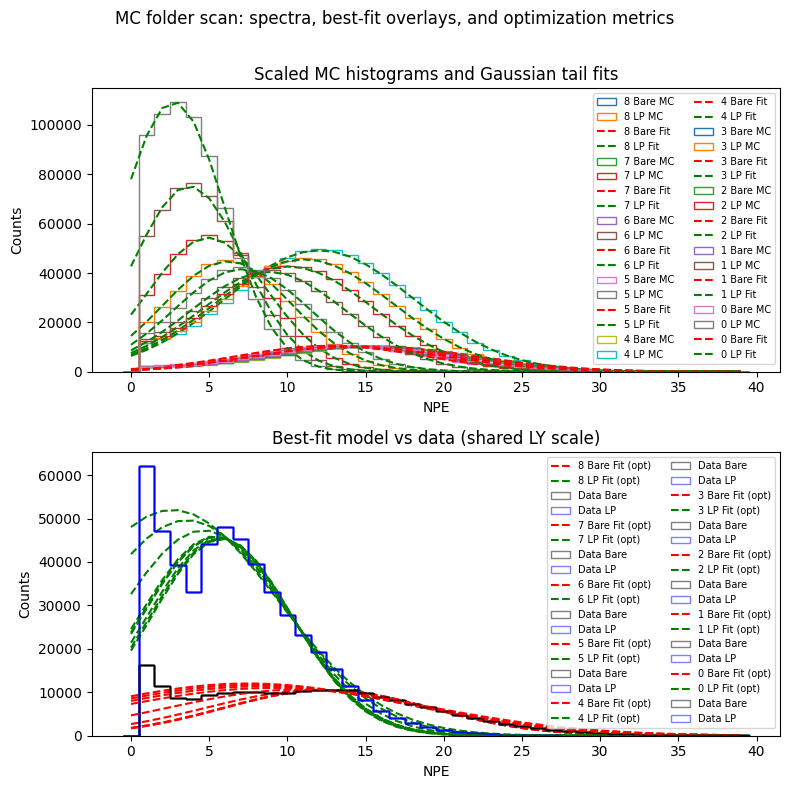

In [54]:
# Updated loop with LY scaling optimization using iminuit
from iminuit import Minuit

overallResults = []
# Get data histograms (use the same ones from earlier)
data_bare_hist = rcBare.mBin_rawCounts

rcLp.setup_forComparison_np(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, qvar=QVAR_USE, peCut=PECUTVALUE) 
data_lp_hist = rcLp.mBin_rawCounts
data_bin_centers = rcBare.mBinX

print("Starting LY scaling optimization for each MC folder...")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))
fig.suptitle("MC folder scan: spectra, best-fit overlays, and optimization metrics")

folders = sorted(os.listdir(g4Path))

for folder in folders[::-1]:  # Test with first 2 folders
  folder_path = os.path.join(g4Path, folder)
  print(f"\n--- Processing folder: {folder_path} ---")
  
  # continue
  # Find LP and bare files in this folder
  lp_files = glob.glob(os.path.join(folder_path, "*LP*"))
  bare_files = glob.glob(os.path.join(folder_path, "*bare*"))
  
  if not lp_files or not bare_files:
    print(f"Skipping {folder}: missing LP or bare files")
    continue
  
  # Take first file of each type (remove .root extension for g4rc)
  lp_file = os.path.splitext(lp_files[0])[0]
  bare_file = os.path.splitext(bare_files[0])[0]
  
  try:
    # Load MC data
    mc_lp = g4rc.FullMCRun(macName=lp_file)
    mc_bare = g4rc.FullMCRun(macName=bare_file)
    
    thisVf = round(float(mc_lp.mPhysPars.vf), 2)
    
    # Setup for comparison using same config
    mc_lp.setup_forComparison(Nbins=conf.Nbins, lowRange=conf.binLow, maxRange=conf.binHigh, variable="mNPE")
    mc_bare.setup_forComparison(Nbins=conf.Nbins, lowRange=conf.binLow, maxRange=conf.binHigh, variable="mNPE")
    
    mc_lp.doCAcorrection_BinomialMC(nCA = conf.NCA)
    mc_bare.doCAcorrection_BinomialMC(nCA = conf.NCA)
    
    ## apply scaling
    pairBare = g4comp.rcMCpair(rcBare, mc_bare)
    pairBare.SetBinRanges(firstBin=conf.rangeLowBare, lastBin=conf.rangeHighBare, mode="x")
    pairLp = g4comp.rcMCpair(rcLp, mc_lp)
    pairLp.SetBinRanges(firstBin=conf.rangeLow, lastBin=conf.rangeHigh, mode="x")
    
    mc_bare.m_scaledCounts = mc_bare.mRaw_Counts * pairBare.GuessScaling() * pairBare.GetPrefac()
    mc_lp.m_scaledCounts = mc_lp.mRaw_Counts * pairLp.GuessScaling() * pairLp.GetPrefac()

    # Fit both histograms with Gaussians
    fit_bare = fit_mc_histogram(mc_bare)
    fit_lp = fit_mc_histogram(mc_lp)
    
    if not (fit_lp.valid and fit_bare.valid):
      print(f"Skipping {folder}: invalid fits")
      continue
    
    # print(fit_bare)
    # print(fit_lp)
    
    ax1.hist(mc_bare.mBinX, mc_bare.mBin_Edges, weights=mc_bare.m_scaledCounts, histtype="step", label=f"{folder} Bare MC")
    ax1.hist(mc_lp.mBinX, mc_lp.mBin_Edges, weights=mc_lp.m_scaledCounts, histtype="step", label=f"{folder} LP MC")
    
    ax1.plot(data_bin_centers, fit_bare.values['amplitude'] * np.exp(-0.5 * ((data_bin_centers - fit_bare.values['mean']) / fit_bare.values['sigma'])**2), 'r--', label=f"{folder} Bare Fit")
    ax1.plot(data_bin_centers, fit_lp.values['amplitude'] * np.exp(-0.5 * ((data_bin_centers - fit_lp.values['mean']) / fit_lp.values['sigma'])**2), 'g--', label=f"{folder} LP Fit")
    
    # Find optimal LY scaling using iminuit (flexSigma: free A, sigma for each; fixed mean ratio from MC)
    opt_result, mean_bare_MC, mean_ratio = fit_ly_flexsigma_iminuit(data_bare_hist, data_lp_hist, fit_bare, fit_lp, data_bin_centers)
    if opt_result.valid:
      Abare_opt     = opt_result.values['Abare']
      ALP_opt       = opt_result.values['ALP']
      LYscale_opt   = opt_result.values['LYscale']
      sigma_bare_opt = opt_result.values['sigma_bare']
      sigma_lp_opt   = opt_result.values['sigma_lp']
      chi2_min = opt_result.fval
      
      mu_bare_data = LYscale_opt * mean_bare_MC
      mu_lp_data   = LYscale_opt * mean_bare_MC * mean_ratio

      print(f"Optimization successful (flexSigma):")
      print(f"  Abare = {Abare_opt:.3f} ± {opt_result.errors['Abare']:.3f}")
      print(f"  ALP   = {ALP_opt:.3f} ± {opt_result.errors['ALP']:.3f}")
      print(f"  vis frac = {thisVf}")
      print(f"  LY scale = {LYscale_opt:.3f} ± {opt_result.errors['LYscale']:.3f}")
      print(f"  sigma_bare = {sigma_bare_opt:.3f} ± {opt_result.errors['sigma_bare']:.3f}")
      print(f"  sigma_lp   = {sigma_lp_opt:.3f} ± {opt_result.errors['sigma_lp']:.3f}")
      print(f"  Min chi2 = {chi2_min:.2f}")
      
      # Store extended results
      result = {
        'folder': folder,
        'lp_mean': fit_lp.values['mean'],
        'bare_mean': fit_bare.values['mean'],
        'mean_bare_MC': mean_bare_MC,
        'mean_ratio': mean_ratio,
        'Abare': Abare_opt,
        'Abare_err': opt_result.errors['Abare'],
        'ALP': ALP_opt,
        'ALP_err': opt_result.errors['ALP'],
        'visFrac': thisVf,
        'LYscale': LYscale_opt,
        'LYscale_err': opt_result.errors['LYscale'],
        'sigma_bare': sigma_bare_opt,
        'sigma_bare_err': opt_result.errors['sigma_bare'],
        'sigma_lp': sigma_lp_opt,
        'sigma_lp_err': opt_result.errors['sigma_lp'],
        'chi2': chi2_min,
        'opt_success': True,
        # also keep raw MC fit params for reference / overlay
        'fit_bare': {'amplitude': fit_bare.values['amplitude'], 'mean': fit_bare.values['mean'], 'sigma': fit_bare.values['sigma']},
        'fit_lp':   {'amplitude': fit_lp.values['amplitude'],   'mean': fit_lp.values['mean'],   'sigma': fit_lp.values['sigma']},
      }

      ax2.plot(data_bin_centers,
               gaussian(data_bin_centers, Abare_opt, mu_bare_data, sigma_bare_opt),
               'r--', label=f"{folder} Bare Fit (opt)")
      ax2.plot(data_bin_centers,
               gaussian(data_bin_centers, ALP_opt, mu_lp_data, sigma_lp_opt),
               'g--', label=f"{folder} LP Fit (opt)")

      ax2.hist(data_bin_centers, bins=rcBare.mBin_edges, weights=data_bare_hist, histtype="step", label="Data Bare", color='black', alpha=0.5)
      ax2.hist(data_bin_centers, bins=rcLp.mBin_edges, weights=data_lp_hist, histtype="step", label="Data LP", color='blue', alpha=0.5)

    else:
      print(f"Optimization failed to converge")
      result = {
        'folder': folder,
        'vis frac': thisVf,
        'lp_mean': fit_lp.values['mean'],
        'bare_mean': fit_bare.values['mean'],
        'opt_success': False
      }
    
    overallResults.append(result)
    
  except Exception as e:
    print(f"Error processing {folder}: {e}")
    continue
  
####### Plotting final results #######
# ax1.legend()
# ax1.set_yscale("log")
ax1.set_title("Scaled MC histograms and Gaussian tail fits")
ax1.set_xlabel("NPE")
ax1.set_ylabel("Counts")
ax1.legend(fontsize=7, ncol=2)

ax2.set_title("Best-fit model vs data (shared LY scale)")
ax2.set_xlabel("NPE")
ax2.set_ylabel("Counts")
ax2.legend(fontsize=7, ncol=2)

## sort organize results by visible fraction
overallResults = sorted(overallResults, key=lambda x: x.get('visFrac', 0))

# Extract data for scatter plots - only successful fits
successful_results = [res for res in overallResults if res.get('opt_success', False)]
x_vf = [round(float(res['visFrac']), 2) for res in successful_results]
yly = [res['LYscale'] for res in successful_results]
ychi2 = [round(res['chi2'], 1) for res in successful_results]

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# print(f"\n--- Summary of optimization results ---")
# for r in results:
#   if r.get('opt_success', False):

#     print(f"Folder {r['folder']}: LY={r['LYscale']:.3f}±{r['LYscale_err']:.3f}, chi2={r['chi2']:.1f}")#     print(f"Folder {r['folder']}: optimization failed")
#   else:

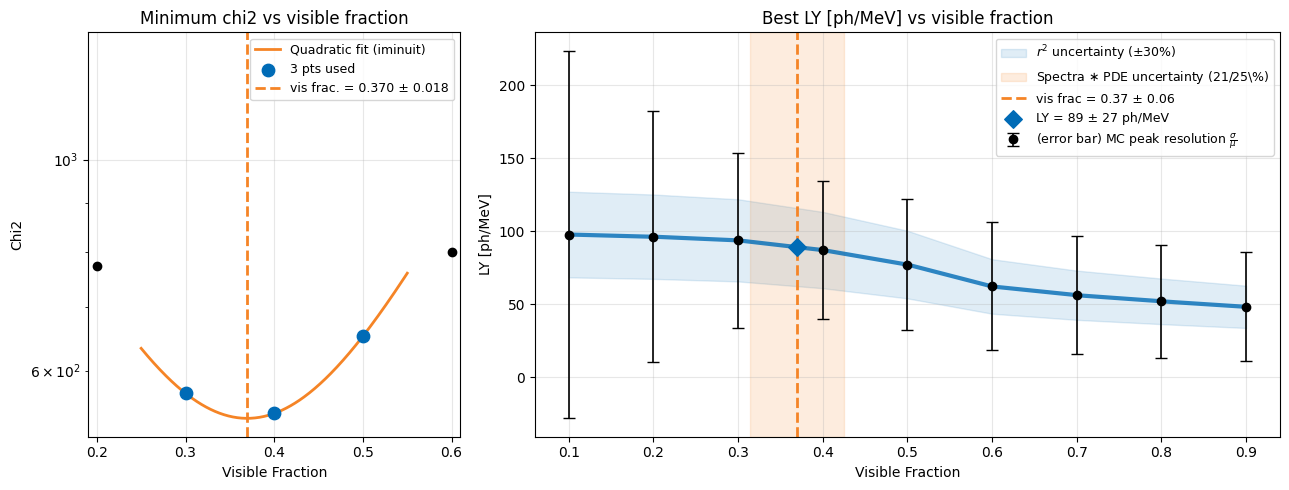

  Visible fraction   vf*  = 0.3695 ± 0.0176
  LY scale        LYs*   = 0.8916 ± 0.0117
  Best Abare             = 10539.9142 ± 43.4866
  Best ALP               = 45963.0998   ± 131.6050
  Best sigma_bare        = 7.2192 ± 0.1170
  Best sigma_lp          = 4.8166   ± 0.0360
  Mean ratio (LP/bare)   = 0.4510  [fixed from MC]
------------------------------------------------------------
  Chi2 (Gauss vs data, bare) = 32.17  (10 bins)
  Chi2 (Gauss vs data, LP)   = 508.83  (7 bins)
  Chi2 total (re-eval)       = 541.00
  NDF (Abare+ALP+LYs+σb+σl) = 12
  Reduced chi2               = 45.083
------------------------------------------------------------
  Fit range bare  [10, 20]  (10 bins)
  Fit range LP    [5, 12]  (7 bins)
  NCA correction         = 0.17
  PE cut                 = 0.5
  Run ID bare            = 202205201136
  Run ID LP              = 202206231023
  Quadratic fit valid    = True
  Quad A  = 6908.3328 ± 2908.2163
  Quad C (chi2 at min)   = 534.6140 ± 21.7917


In [55]:
from iminuit import Minuit
import numpy as np
import matplotlib.container
from matplotlib.legend_handler import HandlerErrorbar

KNICKS_BLUE   = '#006BB6'
KNICKS_ORANGE = '#F58426'

chi2_arr = np.array(ychi2, dtype=float)
vf_arr   = np.array(x_vf,  dtype=float)
ly_arr   = np.array(yly,   dtype=float)

# --- pick 3 lowest chi2 points for quadratic fit ---
idx_sorted = np.argsort(chi2_arr)
idx_low3   = idx_sorted[:3]
vf_low3    = vf_arr[idx_low3]
chi2_low3  = chi2_arr[idx_low3]

# --- iminuit quadratic fit: chi2_val = A*(vf - vf0)^2 + C ---
chi2_err = np.sqrt(chi2_low3)
chi2_err[chi2_err == 0] = 1.0

def quad_model(vf, A, vf0, C):
    return A * (vf - vf0)**2 + C

from iminuit.cost import LeastSquares
cost = LeastSquares(vf_low3, chi2_low3, chi2_err, quad_model)
m_quad = Minuit(cost, A=1.0, vf0=float(vf_low3.mean()), C=float(chi2_low3.min()))
m_quad.limits['A'] = (0, None)
m_quad.limits['C'] = (0, None)
m_quad.migrad()
m_quad.hesse()

vf_star      = m_quad.values['vf0']
vf_star_err  = m_quad.errors['vf0']

# --- interpolate LY scale at vf_star ---
vf_sorted_idx = np.argsort(vf_arr)
ly_interp = float(np.interp(vf_star, vf_arr[vf_sorted_idx], ly_arr[vf_sorted_idx]))

nearest  = np.argsort(np.abs(vf_arr - vf_star))[:2]
dvf      = vf_arr[nearest[0]] - vf_arr[nearest[1]]
dly      = ly_arr[nearest[0]] - ly_arr[nearest[1]]
dly_dvf  = dly / dvf if dvf != 0 else 0.0
ly_err   = abs(dly_dvf) * vf_star_err

# --- best discrete folder and its stored params ---
best_res  = min(successful_results, key=lambda r: r['chi2'])
best_chi2 = best_res['chi2']

n_bare_bins = int((conf.rangeHighBare - conf.rangeLowBare) / conf.binWidth)
n_lp_bins   = int((conf.rangeHigh     - conf.rangeLow)     / conf.binWidth)
ndf_total   = n_bare_bins + n_lp_bins - 5  # free params: Abare, ALP, LYscale, sigma_bare, sigma_lp

# --- re-evaluate chi2 split into bare and LP contributions ---
LY_best        = best_res['LYscale']
mu_bare_best   = LY_best * best_res['mean_bare_MC']
mu_lp_best     = LY_best * best_res['mean_bare_MC'] * best_res['mean_ratio']
sigma_bare_best = best_res['sigma_bare']
sigma_lp_best   = best_res['sigma_lp']
Abare_best     = best_res['Abare']
ALP_best       = best_res['ALP']

mask_bare = (data_bin_centers >= conf.rangeLowBare) & (data_bin_centers <= conf.rangeHighBare)
mask_lp   = (data_bin_centers >= conf.rangeLow)     & (data_bin_centers <= conf.rangeHigh)

pred_bare = gaussian(data_bin_centers[mask_bare], Abare_best, mu_bare_best, sigma_bare_best)
pred_lp   = gaussian(data_bin_centers[mask_lp],   ALP_best,   mu_lp_best,   sigma_lp_best)

err_bare = np.sqrt(data_bare_hist[mask_bare]); err_bare[err_bare == 0] = 1
err_lp   = np.sqrt(data_lp_hist[mask_lp]);     err_lp[err_lp   == 0] = 1

chi2_bare_contrib = float(np.sum((data_bare_hist[mask_bare] - pred_bare)**2 / err_bare**2))
chi2_lp_contrib   = float(np.sum((data_lp_hist[mask_lp]     - pred_lp)**2   / err_lp**2))
chi2_total_reeval = chi2_bare_contrib + chi2_lp_contrib

# --- LY error bars: sigma/mu of fitted data Gaussians ---
ly_yerr = []
for res in successful_results:
    mu_b = res['LYscale'] * res['mean_bare_MC']
    mu_l = res['LYscale'] * res['mean_bare_MC'] * res['mean_ratio']
    frac = 0.5 * np.sqrt((res['sigma_bare'] / mu_b)**2 + (res['sigma_lp'] / mu_l)**2)
    ly_yerr.append(res['LYscale'] * frac)

# ---- flag: plot absolute LY (LYscale * LY_REF) or dimensionless scale ----
PLOT_ABSOLUTE_LY = True   # set True to show LY in ph/MeV
LY_REF = 100.0             # reference LY [ph/MeV]

_lys = LY_REF if PLOT_ABSOLUTE_LY else 1.0
_yly_plot       = [v * _lys for v in yly]
_ly_interp_plot = ly_interp * _lys
_ly_err_plot    = ly_err    * _lys
_ly_yerr_plot   = [e * _lys for e in ly_yerr]
_ylabel         = "LY [ph/MeV]" if PLOT_ABSOLUTE_LY else "LY scale"

# ---- plots ----
fig, (ax4, ax3) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[1, 2])

_vf_total_err = float(np.sqrt(vf_star_err**2 + (0.15 * vf_star)**2))
_ly_total_err = float(np.sqrt(_ly_err_plot**2 + (0.30 * _ly_interp_plot)**2))
_vf_pde_err = 0.15 * abs(vf_star)

# smooth interpolated curve + r^2 shaded band
_vf_line = np.linspace(vf_arr[vf_sorted_idx][0], vf_arr[vf_sorted_idx][-1], 400)
_ly_line  = np.interp(_vf_line, vf_arr[vf_sorted_idx], np.array(_yly_plot)[vf_sorted_idx])
ax3.fill_between(_vf_line, _ly_line * 0.70, _ly_line * 1.30,
                 color=KNICKS_BLUE, alpha=0.12, zorder=1,
                 label=r"$r^2$ uncertainty (±30%)")
ax3.plot(_vf_line, _ly_line, color=KNICKS_BLUE, linewidth=3, linestyle='-', alpha=0.8,
         zorder=2, label="_nolegend_")
ax3.errorbar(x_vf, _yly_plot, yerr=_ly_yerr_plot, fmt='o', color='black', zorder=3,
             capsize=4, elinewidth=1.2, label=r"(error bar) MC peak resolution $\frac{\sigma}{\mu}$")
ax3.axvspan(vf_star - _vf_pde_err, vf_star + _vf_pde_err,
            color=KNICKS_ORANGE, alpha=0.15, zorder=1,
            label=r"Spectra $\ast$ PDE uncertainty (21/25\%)")
ax3.axvline(vf_star, color=KNICKS_ORANGE, linestyle='--', linewidth=2,
            label=f"vis frac = {vf_star:.2f} ± {_vf_pde_err:.2f}")
ax3.scatter([vf_star], [_ly_interp_plot], marker='D', color=KNICKS_BLUE, s=80, zorder=5,
            label=f"LY = {_ly_interp_plot:.0f} ± {_ly_total_err:.0f} ph/MeV")

ax3.set_title(f"Best {_ylabel} vs visible fraction")
ax3.set_ylabel(_ylabel)
ax3.set_xlabel("Visible Fraction")
ax3.legend(fontsize=9, handler_map={matplotlib.container.ErrorbarContainer: HandlerErrorbar(numpoints=1)})
ax3.grid(True, alpha=0.3)
# ax3.set_xlim(0.25, 0.75)

ax4.scatter(x_vf, ychi2, color='black', zorder=3)
ax4.set_yscale("log")
vf_smooth  = np.linspace(vf_low3.min() - 0.05, vf_low3.max() + 0.05, 300)
chi2_curve = quad_model(vf_smooth, m_quad.values['A'], m_quad.values['vf0'], m_quad.values['C'])
ax4.plot(vf_smooth, chi2_curve, color=KNICKS_ORANGE, linewidth=2, label="Quadratic fit (iminuit)")
ax4.scatter(vf_low3, chi2_low3, color=KNICKS_BLUE, zorder=4, s=80, label="3 pts used")
ax4.axvline(vf_star, color=KNICKS_ORANGE, linestyle='--', linewidth=2,
            label=f"vis frac. = {vf_star:.3f} ± {vf_star_err:.3f}")
ax4.set_title("Minimum chi2 vs visible fraction")
ax4.set_xlabel("Visible Fraction")
ax4.set_ylabel("Chi2")
ax4.legend(fontsize=9)

ax4.set_xlim(0.19, 0.61)
# ax4.set_ylim(1e3, ax4.get_ylim()[1])
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---- thesis table summary ----
# ---- thesis table summary ----
print("=" * 60)
print("=" * 60)
print(f"  Visible fraction   vf*  = {vf_star:.4f} ± {vf_star_err:.4f}")
print(f"  LY scale        LYs*   = {ly_interp:.4f} ± {ly_err:.4f}")
print(f"  Best Abare             = {best_res['Abare']:.4f} ± {best_res['Abare_err']:.4f}")
print(f"  Best ALP               = {best_res['ALP']:.4f}   ± {best_res['ALP_err']:.4f}")
print(f"  Best sigma_bare        = {best_res['sigma_bare']:.4f} ± {best_res['sigma_bare_err']:.4f}")
print(f"  Best sigma_lp          = {best_res['sigma_lp']:.4f}   ± {best_res['sigma_lp_err']:.4f}")
print(f"  Mean ratio (LP/bare)   = {best_res['mean_ratio']:.4f}  [fixed from MC]")
print("-" * 60)
print(f"  Chi2 (Gauss vs data, bare) = {chi2_bare_contrib:.2f}  ({n_bare_bins} bins)")
print(f"  Chi2 (Gauss vs data, LP)   = {chi2_lp_contrib:.2f}  ({n_lp_bins} bins)")
print(f"  Chi2 total (re-eval)       = {chi2_total_reeval:.2f}")
print(f"  NDF (Abare+ALP+LYs+σb+σl) = {ndf_total}")
if ndf_total > 0:
    print(f"  Reduced chi2               = {chi2_total_reeval / ndf_total:.3f}")
else:
    print(f"  Reduced chi2               = N/A (NDF=0)")
print("-" * 60)
print(f"  Fit range bare  [{conf.rangeLowBare}, {conf.rangeHighBare}]  ({n_bare_bins} bins)")
print(f"  Fit range LP    [{conf.rangeLow}, {conf.rangeHigh}]  ({n_lp_bins} bins)")
print(f"  NCA correction         = {conf.NCA}")
print(f"  PE cut                 = {PECUTVALUE}")
print(f"  Run ID bare            = {runID_bare[0]}")
print(f"  Run ID LP              = {runID_lp[0]}")
print("=" * 60)
print(f"  Quadratic fit valid    = {m_quad.valid}")
print(f"  Quad A  = {m_quad.values['A']:.4f} ± {m_quad.errors['A']:.4f}")

print(f"  Quad C (chi2 at min)   = {m_quad.values['C']:.4f} ± {m_quad.errors['C']:.4f}")

Plotting MC sims with vf = [0.1, 0.5, 0.9]
Best fit: vf = 0.5


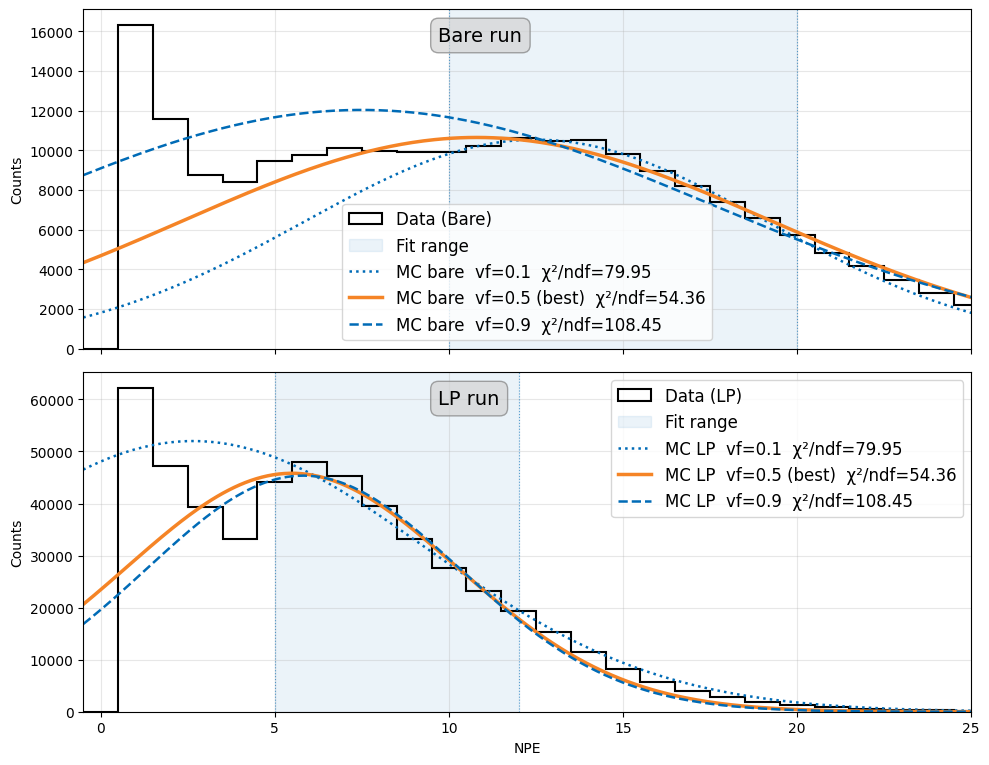

In [59]:
## Clean overlay: data (bare & LP) + 3 selected MC sims as smooth Gaussians
## NY Knicks palette: best fit = solid orange, others = blue dotted/dashed
## Fit params read directly from overallResults — no re-loading or re-fitting

# --- select 3 results ---
by_vf = sorted(successful_results, key=lambda r: float(r['visFrac']))
vf_low_res  = by_vf[0]
vf_high_res = by_vf[-1]
vf_best_res = min(by_vf, key=lambda r: abs(float(r['visFrac']) - 0.5))

seen = {}
for r in [vf_low_res, vf_best_res, vf_high_res]:
    seen[round(float(r['visFrac']), 3)] = r
three_results = sorted(seen.values(), key=lambda r: float(r['visFrac']))

best_vf_key = round(float(vf_best_res['visFrac']), 3)
print("Plotting MC sims with vf =", [round(float(r['visFrac']), 2) for r in three_results])
print(f"Best fit: vf = {round(float(vf_best_res['visFrac']), 2)}")

# --- NY Knicks style ---
KNICKS_BLUE   = '#006BB6'
KNICKS_ORANGE = '#F58426'

non_best_styles = [':', '--']
non_best_idx = 0

def get_style(res):
    global non_best_idx
    if round(float(res['visFrac']), 3) == best_vf_key:
        return KNICKS_ORANGE, '-', 2.5
    else:
        s = non_best_styles[non_best_idx]
        non_best_idx += 1
        return KNICKS_BLUE, s, 1.8

x_smooth = np.linspace(conf.binLow, conf.binHigh, 500)

fig, (axBare, axLP) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# plot data
axBare.hist(data_bin_centers, bins=rcBare.mBin_edges, weights=data_bare_hist,
            histtype="step", color='black', linewidth=1.5, label="Data (Bare)")
axLP.hist(data_bin_centers, bins=rcLp.mBin_edges, weights=data_lp_hist,
          histtype="step", color='black', linewidth=1.5, label="Data (LP)")

# draw chi2 fitting ranges
axBare.axvspan(conf.rangeLowBare, conf.rangeHighBare, alpha=0.08, color=KNICKS_BLUE, label="Fit range")
axBare.axvline(conf.rangeLowBare, color=KNICKS_BLUE, linestyle=':', linewidth=0.8, alpha=0.6)
axBare.axvline(conf.rangeHighBare,    color=KNICKS_BLUE, linestyle=':', linewidth=0.8, alpha=0.6)

axLP.axvspan(conf.rangeLow, conf.rangeHigh, alpha=0.08, color=KNICKS_BLUE, label="Fit range")
axLP.axvline(conf.rangeLow,  color=KNICKS_BLUE, linestyle=':', linewidth=0.8, alpha=0.6)
axLP.axvline(conf.rangeHigh, color=KNICKS_BLUE, linestyle=':', linewidth=0.8, alpha=0.6)

# overlay Gaussian curves — params read straight from stored results
non_best_idx = 0
for res in three_results:
    col, ls, lw = get_style(res)

    LYs      = res['LYscale']
    Abare    = res['Abare']
    ALP      = res['ALP']
    mu_bare  = LYs * res['mean_bare_MC']
    mu_lp    = LYs * res['mean_bare_MC'] * res['mean_ratio']
    sig_b    = res['sigma_bare']
    sig_l    = res['sigma_lp']
    vf_label = round(float(res['visFrac']), 2)
    is_best  = round(float(res['visFrac']), 3) == best_vf_key
    chi2_ndf = res['chi2'] / ndf_total if ndf_total > 0 else float('nan')
    suffix   = " (best)" if is_best else ""

    y_bare = gaussian(x_smooth, Abare, mu_bare, sig_b)
    y_lp   = gaussian(x_smooth, ALP,   mu_lp,   sig_l)

    axBare.plot(x_smooth, y_bare, color=col, linestyle=ls, linewidth=lw,
                label=f"MC bare  vf={vf_label}{suffix}  \u03c7\u00b2/ndf={chi2_ndf:.2f}")
    axLP.plot(x_smooth, y_lp,   color=col, linestyle=ls, linewidth=lw,
              label=f"MC LP  vf={vf_label}{suffix}  \u03c7\u00b2/ndf={chi2_ndf:.2f}")

_label_props = dict(boxstyle='round,pad=0.4', facecolor='lightgray', alpha=0.7, edgecolor='gray')
for ax, title in [(axBare, "Bare run"), (axLP, "LP run")]:
    ax.text(0.4, 0.95, title, transform=ax.transAxes, fontsize=14,
            verticalalignment='top', bbox=_label_props)
    ax.set_ylabel("Counts")
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(conf.binLow, 25)

axLP.set_xlabel("NPE")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [57]:
## compute the PE mean of each data histogram. just print it

def compute_pe_mean(bin_centers, counts):
    total_counts = np.sum(counts)
    if total_counts == 0:
        return 0
    mean_pe = np.sum(bin_centers * counts) / total_counts
    return mean_pe
  
mean_pe_bare = compute_pe_mean(data_bin_centers, data_bare_hist)
mean_pe_lp   = compute_pe_mean(data_bin_centers, data_lp_hist)

print(f"Mean PE (data, bare) = {mean_pe_bare:.2f}")
print(f"Mean PE (data, LP)   = {mean_pe_lp:.2f}")

Mean PE (data, bare) = 11.40
Mean PE (data, LP)   = 6.65
